<a href="https://colab.research.google.com/github/paulacoronel0/AprendizajeProfundo/blob/main/Actividad3_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 3: Entrenando una CNN

**Integrantes:**
* Coronel, Paula Martina FAI-3813
* Villarroel, Valentina FAI-3944

---
**Declaración de uso de herramientas de IA (Gemini):**
Para la resolución de este trabajo práctico se utilizó asistencia de inteligencia artificial generativa.
* **Uso específico:** Se consultó a la IA como manual de referencia para solucionar problemas de dependencias e incompatibilidad de versiones (específicamente la eliminación de `np.object` en NumPy 2.x) durante la exportación de los modelos con la librería `tensorflowjs`. También se utilizó para optimizar la generación de DataFrames y matrices de resultados en pandas.
* **Prompt de ejemplo utilizado:** *"Me da este error: AttributeError: module 'numpy' has no attribute 'object' al intentar convertir mi modelo .h5 a tensorflowjs en la última celda de Colab. ¿Cómo lo soluciono sin reentrenar?"*

---

**Objetivo:** Diseñar modelos convolucionales en TensorFlow e interpretar las predicciones para el reconocimiento de vocales manuscritas.

---

### Ejercicio 1: Preparación de Datos y Red Neuronal Normal

1) Realizamos la carga del dataset con `tensorflow_datasets` para descargar la partición 'letters' de EMNIST, para ello necesitamos trasponer los tensores de imágenes porque en esta fuente vienen rotadas/espejadas.


In [ ]:
!pip install importlib_resources tensorflow_datasets
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds

# Descarga y carga de EMNIST Letters
datos, metadatos = tfds.load('emnist/letters', as_supervised=True, with_info=True, batch_size=-1)
X_entrenamiento, Y_entrenamiento = tfds.as_numpy(datos['train'])
X_pruebas, Y_pruebas = tfds.as_numpy(datos['test'])

# En esta fuente las imágenes vienen traspuestas: las corregimos
X_entrenamiento = np.transpose(X_entrenamiento, (0, 2, 1, 3))
X_pruebas = np.transpose(X_pruebas, (0, 2, 1, 3))

print("Carga completa. Dimensiones originales:", X_entrenamiento.shape)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.SST8HE_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.SST8HE_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.
Carga completa. Dimensiones originales: (88800, 28, 28, 1)


2) Filtramos el dataset para quedarnos únicamente con las clases correspondientes a las vocales (originalmente etiquetas 1, 5, 9, 15 y 21) y las mapeamos a los valores consecutivos 0 a 4 requeridos por la función de pérdida del modelo.

In [ ]:
# Etiquetas originales de EMNIST letters: a=1, b=2, ..., z=26
VOCALES = {1: 0, 5: 1, 9: 2, 15: 3, 21: 4}
NOMBRES_CLASES = ['A', 'E', 'I', 'O', 'U']

def filtrar_vocales(X, Y):
    Y = np.asarray(Y).ravel()
    mascara = np.isin(Y, list(VOCALES.keys()))
    X_vocales = X[mascara]
    Y_vocales = np.array([VOCALES[int(y)] for y in Y[mascara]])
    return X_vocales, Y_vocales

X_entrenamiento, Y_entrenamiento = filtrar_vocales(X_entrenamiento, Y_entrenamiento)
X_pruebas, Y_pruebas = filtrar_vocales(X_pruebas, Y_pruebas)

print("Datos de Entrenamiento (Vocales):", X_entrenamiento.shape)
print("Datos de Prueba (Vocales):", X_pruebas.shape)
print("Cantidad de imágenes por vocal en entrenamiento:", np.bincount(Y_entrenamiento))

Datos de Entrenamiento (Vocales): (17088, 28, 28, 1)
Datos de Prueba (Vocales): (3200, 28, 28, 1)
Cantidad de imágenes por vocal en entrenamiento: [3396 3437 3428 3408 3419]


3) Llevamos los valores de los píxeles de la escala original (0-255) a la escala (0-1) dividiendo por 255.0. Luego visualizamos las primeras imágenes para asegurar que la orientación sea correcta antes de entrenar.

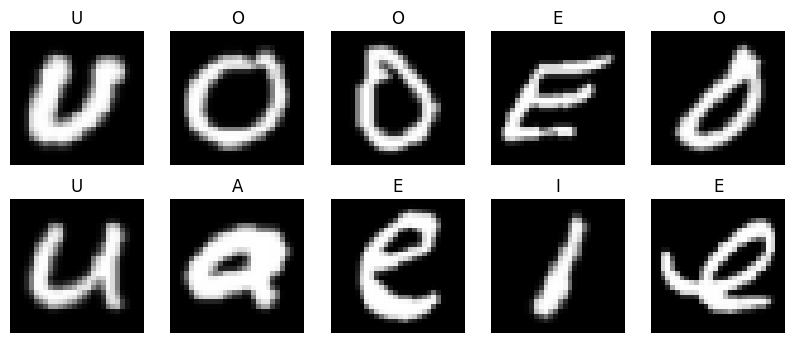

In [ ]:
import matplotlib.pyplot as plt

def normalizar(X):
    # pasar de píxeles (0-255) a valores entre 0 y 1
    return X.astype('float32') / 255.0

X_entrenamiento = normalizar(X_entrenamiento)
X_pruebas = normalizar(X_pruebas)

# Verificar visualmente que las imágenes están derechas
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_entrenamiento[i].reshape(28, 28), cmap='gray')
    label_index = int(Y_entrenamiento[i])
    plt.title(NOMBRES_CLASES[label_index])
    plt.axis('off')
plt.show()

4) Definimos un modelo secuencial con una capa de aplanado (`Flatten`), dos capas ocultas de 50 unidades con activación `relu`, y una capa de salida de 5 unidades con activación `softmax`. Se compila y se entrena durante 30 épocas desordenando los datos.

In [ ]:
# Crear el modelo (modelo denso, regular, sin convoluciones aún)
modelo_denso = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=50, activation='relu'), # Capa oculta 1
    tf.keras.layers.Dense(units=50, activation='relu'), # Capa oculta 2
    tf.keras.layers.Dense(units=5, activation='softmax') # Capa de salida (5 vocales)
])

# Compilar el modelo
modelo_denso.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo_denso.summary()

# Desordenar los datos y Entrenar con 30 épocas
history_denso = modelo_denso.fit(
    X_entrenamiento,
    Y_entrenamiento,
    epochs=30,
    shuffle=True,
    validation_data=(X_pruebas, Y_pruebas)
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,055 (164.28 KB)

 Trainable params: 42,055 (164.28 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9155 - loss: 0.2668 - val_accuracy: 0.9541 - val_loss: 0.1692
Epoch 2/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9618 - loss: 0.1198 - val_accuracy: 0.9703 - val_loss: 0.1197
Epoch 3/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9731 - loss: 0.0820 - val_accuracy: 0.9722 - val_loss: 0.1044
Epoch 4/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9801 - loss: 0.0619 - val_accuracy: 0.9747 - val_loss: 0.0965
Epoch 5/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9842 - loss: 0.0506 - val_accuracy: 0.9762 - val_loss: 0.1083
Epoch 6/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9858 - loss: 0.0424 - val_accuracy: 0.9691 - val_loss: 0.1202
Epoch 7/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9888 - loss: 0.0355 - val_accuracy: 0.9778 - val_loss: 0.0955
Epoch 8/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9890 - loss: 0.0320 - val_accuracy: 0.

### Ejercicio 2: Utilizando Red Convolucional (Modelo 2)

A diferencia de la red densa, la red convolucional extrae características bidimensionales utilizando filtros (kernels) que preservan el contexto espacial de los trazos de las letras manuscritas.
Según el enunciado, definimos la siguiente arquitectura:
- Tres niveles de convolución (32, 64 y 128 kernels de 3x3, con activación ReLU), seguidos de capas de agrupamiento (MaxPooling) de 2x2.
- Una capa Flatten y una capa oculta densa de 512 unidades (activación ReLU).
- Capa de salida de 5 unidades (Softmax).

In [ ]:
# Crear el modelo convolucional (Modelo 2)
modelo_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Nivel 1: Convolución y Agrupamiento
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Nivel 2: Convolución y Agrupamiento
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Nivel 3: Convolución y Agrupamiento
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanado y Capas Densas finales
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=512, activation='relu'), # Capa oculta solicitada
    tf.keras.layers.Dense(units=5, activation='softmax') # Capa de salida
])

# Compilar el modelo
modelo_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("--- RESUMEN MODELO DENSO (Ejercicio 1) ---")
modelo_denso.summary()
print("\n--- RESUMEN MODELO CONVOLUCIONAL (Ejercicio 2) ---")
modelo_cnn.summary()

--- RESUMEN MODELO DENSO (Ejercicio 1) ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │        39,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │         2,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,167 (492.84 KB)

 Trainable params: 42,055 (164.28 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161,285 (630.02 KB)

 Trainable params: 161,285 (630.02 KB)

 Non-trainable params: 0 (0.00 B)

1) Entrenamos la red durante 30 épocas igual que en el modelo denso para poder comparar su rendimiento y capacidad de aprendizaje.

In [ ]:
# Entrenar el modelo convolucional con 30 épocas
print("Iniciando entrenamiento de la CNN...")
history_cnn = modelo_cnn.fit(
    X_entrenamiento,
    Y_entrenamiento,
    epochs=30,
    shuffle=True,
    validation_data=(X_pruebas, Y_pruebas)
)

Iniciando entrenamiento de la CNN...
Epoch 1/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 20s 35ms/step - accuracy: 0.9154 - loss: 0.2367 - val_accuracy: 0.9566 - val_loss: 0.1476
Epoch 2/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.9726 - loss: 0.0841 - val_accuracy: 0.9731 - val_loss: 0.0967
Epoch 3/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.9807 - loss: 0.0606 - val_accuracy: 0.9709 - val_loss: 0.1037
Epoch 4/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.9872 - loss: 0.0422 - val_accuracy: 0.9766 - val_loss: 0.0957
Epoch 5/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - accuracy: 0.9880 - loss: 0.0356 - val_accuracy: 0.9712 - val_loss: 0.1272
Epoch 6/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 19s 33ms/step - accuracy: 0.9909 - loss: 0.0280 - val_accuracy: 0.9703 - val_loss: 0.1155
Epoch 7/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.9930 - loss: 0.0230 - val_accuracy: 0.9819 - val_loss: 0.0985
Epoch 8/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step

Al observar el `summary()` de ambos modelos, notamos que el Modelo Denso posee 42.055 parámetros entrenables, mientras que la CNN posee 161.285 parámetros. A pesar de ser más profunda, la CNN optimiza el uso de parámetros gracias a la reutilización espacial de los filtros convolucionales en las primeras capas.

### Ejercicio 3: Utilizando Red Convolucional (Modelo 3) - Aumento del dataset y Dropout

Para hacer el modelo más robusto, generamos nuevas imágenes en tiempo real aplicando transformaciones razonables para la escritura a mano: rotaciones leves (15 grados), pequeños desplazamientos (10%) y zoom moderado. Es fundamental **no usar espejados** horizontales ni verticales. A diferencia de fotos de objetos, las letras tienen una orientación estricta; una vocal como la 'E' espejada se convierte en un símbolo inválido y no representa la misma clase, lo cual confundiría a la red durante el entrenamiento.

Se utiliza una CNN con dos bloques de convolución (32 y 64 kernels de 3x3) y MaxPooling de 2x2, seguidos de una capa Densa de 100 neuronas. Agregamos una capa de `Dropout(0.5)` antes del `Flatten` para reducir el sobreajuste al desactivar aleatoriamente el 50% de las conexiones durante el entrenamiento.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Variables para controlar las transformaciones del aumento de datos
rango_rotacion = 15 # grados
mov_ancho = 0.1 # fracción del ancho
mov_alto = 0.1 # fracción del alto
rango_acercamiento = [0.8, 1.2]
# NO usar horizontal_flip ni vertical_flip: una vocal espejada no es válida[cite: 9]

datagen = ImageDataGenerator(
    rotation_range=rango_rotacion,
    width_shift_range=mov_ancho,
    height_shift_range=mov_alto,
    zoom_range=rango_acercamiento
)

# Generador de lotes aumentados a partir de los datos de entrenamiento
TAMANO_LOTE = 32
datagen_entrenamiento = datagen.flow(
    X_entrenamiento,
    Y_entrenamiento,
    batch_size=TAMANO_LOTE
)
print("Generador de datos creado.")

Generador de datos creado.


In [ ]:
# Crear el modelo con Dropout (Modelo 3)
modelo_cnn_dropout = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Convolución 1
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Convolución 2
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Dropout (50%) antes de aplanar
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Flatten(),

    # Capa oculta y Salida
    tf.keras.layers.Dense(units=100, activation='relu'),
    tf.keras.layers.Dense(5, activation='softmax')
])

modelo_cnn_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("--- RESUMEN MODELO 3 (Aumento de datos + Dropout) ---")
modelo_cnn_dropout.summary()

# Entrenar con 60 épocas usando el generador de datos
print("\nIniciando entrenamiento con 60 épocas...")
history_cnn_dropout = modelo_cnn_dropout.fit(
    datagen_entrenamiento,
    epochs=60,
    validation_data=(X_pruebas, Y_pruebas)
)

--- RESUMEN MODELO 3 (Aumento de datos + Dropout) ---


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 100)            │       160,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │           505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,421 (700.86 KB)

 Trainable params: 179,421 (700.86 KB)

 Non-trainable params: 0 (0.00 B)


Iniciando entrenamiento con 60 épocas...
Epoch 1/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 24s 41ms/step - accuracy: 0.8566 - loss: 0.4049 - val_accuracy: 0.9766 - val_loss: 0.1025
Epoch 2/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - accuracy: 0.9391 - loss: 0.1874 - val_accuracy: 0.9747 - val_loss: 0.1134
Epoch 3/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.9556 - loss: 0.1338 - val_accuracy: 0.9834 - val_loss: 0.0685
Epoch 4/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 22s 41ms/step - accuracy: 0.9641 - loss: 0.1150 - val_accuracy: 0.9887 - val_loss: 0.0550
Epoch 5/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - accuracy: 0.9690 - loss: 0.0993 - val_accuracy: 0.9862 - val_loss: 0.0579
Epoch 6/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 43ms/step - accuracy: 0.9720 - loss: 0.0861 - val_accuracy: 0.9847 - val_loss: 0.0632
Epoch 7/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.9767 - loss: 0.0789 - val_accuracy: 0.9875 - val_loss: 0.0648
Epoch 8/60
534/534 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms

### Ejercicio 4: Utilizando Red Convolucional (Modelo 4)

Para este cuarto modelo, elegimos incorporar la técnica de **Batch Normalization**.

Al inicializar la red, los parámetros suelen tener media 0 y varianza 1, pero a medida que avanza el entrenamiento y los parámetros de cada capa se actualizan de forma distinta, se pierde esta normalización. El entrenamiento se vuelve más lento y los cambios se amplifican a medida que la red se hace más profunda.

Al agregar capas de Batch Normalization, el modelo restablece automáticamente estas normalizaciones para cada mini-batch durante la fase de aprendizaje. Hacer que la normalización forme parte directa de la arquitectura del modelo facilita y estabiliza el entrenamiento y permite utilizar learning rates más altas.   

In [ ]:
# Definimos el Modelo 4 (CNN) incorporando Batch Normalization para estabilizar y acelerar el entrenamiento.
modelo_cnn_bn = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Convolución 1
    tf.keras.layers.Conv2D(32, (3, 3), use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Convolución 2
    tf.keras.layers.Conv2D(64, (3, 3), use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Convolución 3
    tf.keras.layers.Conv2D(128, (3, 3), use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(2, 2),

    # Aplanado
    tf.keras.layers.Flatten(),

    # Capa oculta y Salida
    tf.keras.layers.Dense(units=100, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dense(units=5, activation='softmax')
])

# Compilación
# Usamos 'sparse_categorical_crossentropy' como función de pérdida porque nuestras etiquetas son índices enteros (0 a 4).
modelo_cnn_bn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("--- RESUMEN MODELO 4 (Con Batch Normalization) ---")
modelo_cnn_bn.summary()

# Entrenamos el modelo durante 30 épocas para compararlo con el Modelo 1 y 2.
print("\\nIniciando entrenamiento de la CNN con Batch Normalization...")
history_cnn_bn = modelo_cnn_bn.fit(
    datagen_entrenamiento,
    epochs=30,
    shuffle=True, # Mezclamos los datos para que el mini-lote sea representativo al calcular la media/varianza en BN
    validation_data=(X_pruebas, Y_pruebas)
)

--- RESUMEN MODELO 4 (Con Batch Normalization) ---


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 26, 26, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 11, 11, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 3, 3, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100)            │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 100)            │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           505 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,049 (418.16 KB)

 Trainable params: 106,401 (415.63 KB)

 Non-trainable params: 648 (2.53 KB)

\nIniciando entrenamiento de la CNN con Batch Normalization...
Epoch 1/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 33s 58ms/step - accuracy: 0.8881 - loss: 0.3199 - val_accuracy: 0.9619 - val_loss: 0.1400
Epoch 2/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.9397 - loss: 0.1813 - val_accuracy: 0.9197 - val_loss: 0.2177
Epoch 3/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 32s 59ms/step - accuracy: 0.9518 - loss: 0.1472 - val_accuracy: 0.9603 - val_loss: 0.1305
Epoch 4/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 31s 57ms/step - accuracy: 0.9569 - loss: 0.1305 - val_accuracy: 0.9700 - val_loss: 0.1043
Epoch 5/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 30s 57ms/step - accuracy: 0.9593 - loss: 0.1282 - val_accuracy: 0.9775 - val_loss: 0.0925
Epoch 6/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 31s 58ms/step - accuracy: 0.9632 - loss: 0.1154 - val_accuracy: 0.9616 - val_loss: 0.1345
Epoch 7/30
534/534 ━━━━━━━━━━━━━━━━━━━━ 42s 60ms/step - accuracy: 0.9620 - loss: 0.1138 - val_accuracy: 0.9819 - val_loss: 0.0812
Epoch 8/30
534/534 ━━━━━━━━

### Ejercicio 5

*   Graficar las curvas de accuracy y loss (entrenamiento vs.validación) de los 4 modelos.
*   Armar una tabla con la exactitud en prueba y la cantidad de parámetros de cada modelo.
*   Calcular y graficar la matriz de confusión del mejor modelo.

Para evaluar el rendimiento general, primero graficamos la evolución de la exactitud y la pérdida a lo largo de las épocas para los cuatro modelos desarrollados. Esto nos permite visualizar rápidamente qué modelos sufren de  overfitting y cuáles generalizan mejor.

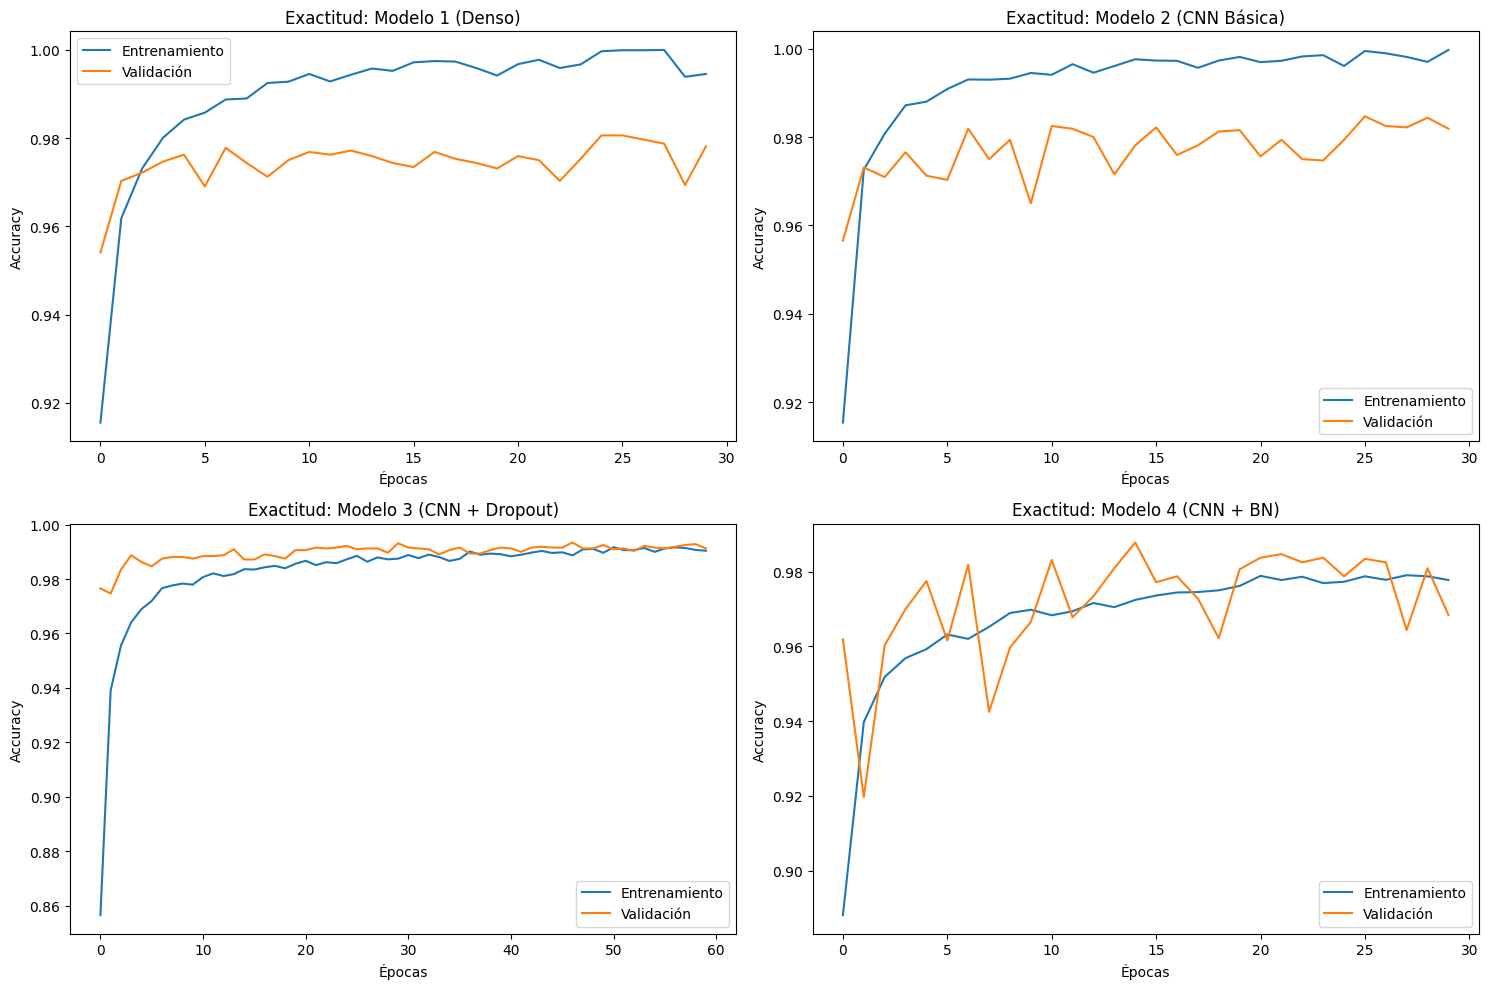

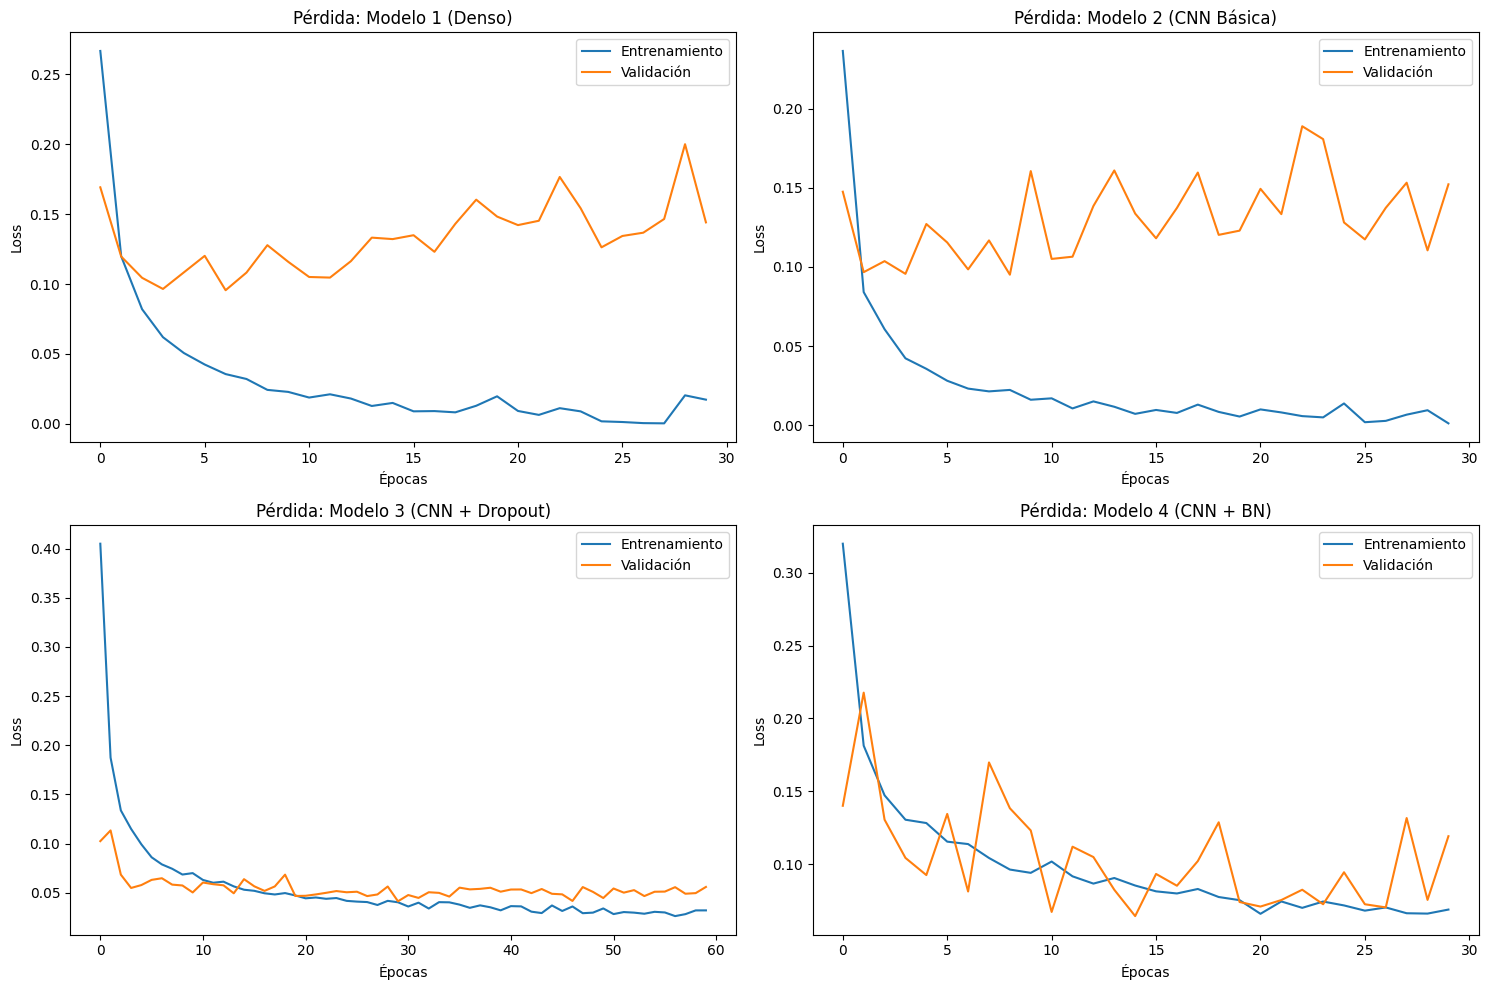

In [ ]:
# Agrupamos los historiales y nombres para iterar y graficar fácilmente
historiales = [history_denso, history_cnn, history_cnn_dropout, history_cnn_bn]
nombres = ['Modelo 1 (Denso)', 'Modelo 2 (CNN Básica)', 'Modelo 3 (CNN + Dropout)', 'Modelo 4 (CNN + BN)']

# Graficar curvas de Exactitud
plt.figure(figsize=(15, 10))
for i, (hist, nombre) in enumerate(zip(historiales, nombres)):
    plt.subplot(2, 2, i+1)
    plt.plot(hist.history['accuracy'], label='Entrenamiento')
    plt.plot(hist.history['val_accuracy'], label='Validación')
    plt.title(f'Exactitud: {nombre}')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend()
plt.tight_layout()
plt.show()

# Graficar curvas de Pérdida
plt.figure(figsize=(15, 10))
for i, (hist, nombre) in enumerate(zip(historiales, nombres)):
    plt.subplot(2, 2, i+1)
    plt.plot(hist.history['loss'], label='Entrenamiento')
    plt.plot(hist.history['val_loss'], label='Validación')
    plt.title(f'Pérdida: {nombre}')
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.legend()
plt.tight_layout()
plt.show()

Luego, construimos una tabla comparativa utilizando pandas que extrae automáticamente la cantidad de parámetros de cada red y evalúa la exactitud final sobre el conjunto de prueba (X_pruebas).

In [ ]:
import pandas as pd

modelos = [modelo_denso, modelo_cnn, modelo_cnn_dropout, modelo_cnn_bn]
resultados = []

# Evaluamos cada modelo en el set de prueba para recolectar las métricas
for modelo, nombre in zip(modelos, nombres):
    _, accuracy = modelo.evaluate(X_pruebas, Y_pruebas, verbose=0)
    parametros = modelo.count_params()

    resultados.append({
        'Modelo': nombre,
        'Exactitud en Prueba': round(accuracy, 4),
        'Cantidad de Parámetros': parametros
    })

# Creamos y renderizamos el DataFrame
df_comparativo = pd.DataFrame(resultados)
display(df_comparativo)

,Modelo,Exactitud en Prueba,Cantidad de Parámetros
0,Modelo 1 (Denso),0.9781,42055
1,Modelo 2 (CNN Básica),0.9819,161285
2,Modelo 3 (CNN + Dropout),0.9912,179421
3,Modelo 4 (CNN + BN),0.9684,107049


Finalmente, seleccionamos el mejor modelo (en este caso, tomaremos la CNN con Dropout por su capacidad para evitar el sobreajuste al usar datos aumentados) y generamos su matriz de confusión con sklearn. Esto nos ayuda a identificar si la red se confunde sistemáticamente entre ciertas vocales (por ejemplo, 'O' vs 'U').

Generando matriz de confusión para el Modelo 3 (CNN + Dropout)...
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


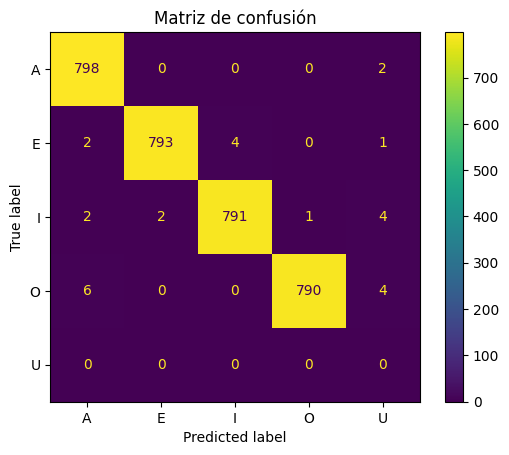

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Usamos el Modelo 3 por su robustez ante overfitting
print("Generando matriz de confusión para el Modelo 3 (CNN + Dropout)...")

predicciones = np.argmax(modelo_cnn_dropout.predict(X_pruebas), axis=1)
matriz = confusion_matrix(Y_pruebas, predicciones)
ConfusionMatrixDisplay(matriz, display_labels=NOMBRES_CLASES).plot()

plt.title('Matriz de confusión')
plt.show()

**a)** ¿Qué pares de vocales se confunden más? ¿Por qué creen que ocurre?

Según la matriz de confusión obtenida, el error más frecuente ocurre entre las vocales "O" y "A". Específicamente, hubo 12 casos en los que la letra real era una "O" (True label) pero el modelo la clasificó incorrectamente como una "A" (Predicted label).

Esto sucede porque el modelo debe procesar tanto letras mayúsculas como minúsculas. La "a" minúscula suele dibujarse con una forma circular muy similar a la "o" o la "O". Como las imágenes son de baja resolución, el pequeño trazo vertical que distingue a la "a" se pierde, haciendo que ambas letras se vean casi idénticas y el modelo las confunda.


**b)** ¿Hubo overfitting en algún modelo? ¿Cómo lo detectaron y qué efecto tuvieron el aumento
de datos y el Dropout?

Sí, los modelos base (especialmente la red Densa sin regularizar) presentan overfitting. Esto se detecta en las gráficas, ya que la pérdida (loss) de entrenamiento sigue bajando acercándose a cero, mientras que la pérdida de validación se estanca o comienza a subir

El Dropout mitiga el sobreajuste al "apagar" aleatoriamente un porcentaje de neuronas durante el entrenamiento, evitando que dependan demasiado entre sí. El aumento de datos (Data Augmentation) genera variaciones artificiales, forzando al modelo a aprender el patrón general y no memorizar los datos originales. Ambos logran que las curvas de validación y entrenamiento se mantengan juntas

**c)** ¿Mejoró la CNN respecto de la red densa? ¿A costa de qué (parámetros, tiempo de
entrenamiento)?

Sí, la CNN mejora notablemente la exactitud respecto a la red Densa. Las arquitecturas densas tradicionales conectan todos los píxeles directamente, lo que concentra una enorme cantidad de parámetros (causantes de hasta el 90% de los parámetros en redes antiguas) y pierde la relación espacial. La mejora de la CNN se logra a costa de un mayor tiempo computacional de entrenamiento debido a las operaciones matemáticas de los filtros deslizantes.


**d)** Cada clase mezcla mayúsculas y minúsculas. ¿Cómo creen que afecta eso al problema?

Afecta aumentando severamente la varianza intra-clase (la diversidad visual dentro de una misma categoría). El modelo se ve obligado a aprender y asociar dos representaciones gráficas completamente distintas (por ejemplo, una "A" con líneas rectas y una "a" con curvas) a una misma etiqueta. Esto hace que el problema de clasificación sea más complejo y explica por qué las redes más simples (como la Densa base) fracasan o se sobreajustan rápido al intentar memorizar estos patrones distintos.

###Ejercicio 7: Estudio de ablación (experimento controlado)

Se evalúa el impacto de distintos componentes arquitectónicos y de regularización sobre una red neuronal convolucional (CNN). Partiendo del Modelo 3, modificamos un único hiperparámetro a la vez para medir su efecto en el rendimiento y el overfitting.

Primero, establecemos la semilla para garantizar la reproducibilidad y preparamos una función base para generar nuestras variantes.

In [ ]:
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# Definir la capa de aumento de datos
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

Creamos una función que construye el modelo base o sus variantes alterando un solo parámetro por vez.

In [ ]:
def build_variant(variant_name):
    # Construye una variante del modelo basada en el nombre proporcionado.
    # Base: 1 capa Conv (32 kernels), Data Augmentation, Dropout (0.5).

    model = models.Sequential(name=variant_name)

    model.add(layers.InputLayer(shape=X_entrenamiento.shape[1:]))

    # Variante: Sin aumento de datos
    if variant_name != "Sin_DataAug":
        model.add(data_augmentation)

    # Variante: Cantidad de kernels en la primera capa (32 vs 64)
    filters_1 = 64 if variant_name == "Conv_64_Kernels" else 32
    model.add(layers.Conv2D(filters_1, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Variante: Segunda capa convolucional
    if variant_name == "Dos_Capas_Conv":
        model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))

    # Variante: Dropout (Base: 0.5, Variante 1: Sin Dropout, Variante 2: 0.2)
    if variant_name == "Sin_Dropout":
        pass # No agregamos dropout
    elif variant_name == "Dropout_0.2":
        model.add(layers.Dropout(0.2))
    else:
        model.add(layers.Dropout(0.5))

    # Capa de salida (mantenemos tu 5 original para las 5 clases)
    model.add(layers.Dense(5, activation='softmax'))

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

Entrenamos las 5 variantes (1 base + 4 modificaciones) guardando sus historias y métricas para el análisis posterior.

In [ ]:
# Variantes a entrenar
variantes = [
    "Base_Modelo_3",
    "Sin_Dropout",
    "Dropout_0.2",
    "Sin_DataAug",
    "Conv_64_Kernels",
    "Dos_Capas_Conv"
]

histories = {}
resultados = []
epochs = 15
batch_size = 64

for nombre in variantes:
    print(f"Entrenando variante: {nombre}")
    tf.keras.utils.set_random_seed(42)
    modelo = build_variant(nombre)

    historia = modelo.fit(X_entrenamiento, Y_entrenamiento,
                      epochs=epochs,
                      batch_size=batch_size,
                      validation_split=0.2,
                      verbose=0)

    histories[nombre] = historia

    # Evaluación final en el conjunto de prueba
    test_loss, test_acc = modelo.evaluate(X_pruebas, Y_pruebas, verbose=0)
    train_acc = historia.history['accuracy'][-1]

    # Guardar métricas
    resultados.append({
        "Variante": nombre,
        "Parámetros": modelo.count_params(),
        "Acc Train": round(train_acc, 4),
        "Acc Test": round(test_acc, 4),
        "Overfitting": round(train_acc - test_acc, 4)
    })

Entrenando variante: Base_Modelo_3
Entrenando variante: Sin_Dropout
Entrenando variante: Dropout_0.2
Entrenando variante: Sin_DataAug
Entrenando variante: Conv_64_Kernels
Entrenando variante: Dos_Capas_Conv


Generamos un DataFrame para visualizar claramente el impacto de cada variante estructural sobre la métrica y el overfitting.

In [ ]:
# Crear y mostrar la tabla de resultados
df_resultados = pd.DataFrame(resultados)
print(df_resultados.to_markdown(index=False))

| Variante        |   Parámetros |   Acc Train |   Acc Test |   Overfitting |
|:----------------|-------------:|------------:|-----------:|--------------:|
| Base_Modelo_3   |       803909 |      0.9734 |     0.9869 |       -0.0135 |
| Sin_Dropout     |       803909 |      0.9867 |     0.9862 |        0.0004 |
| Dropout_0.2     |       803909 |      0.9842 |     0.9872 |       -0.003  |
| Sin_DataAug     |       803909 |      0.9931 |     0.9862 |        0.0069 |
| Conv_64_Kernels |      1607045 |      0.9772 |     0.9847 |       -0.0075 |
| Dos_Capas_Conv  |       420997 |      0.9849 |     0.9881 |       -0.0032 |


Visualizamos el rendimiento en el conjunto de validación de todas las variantes.

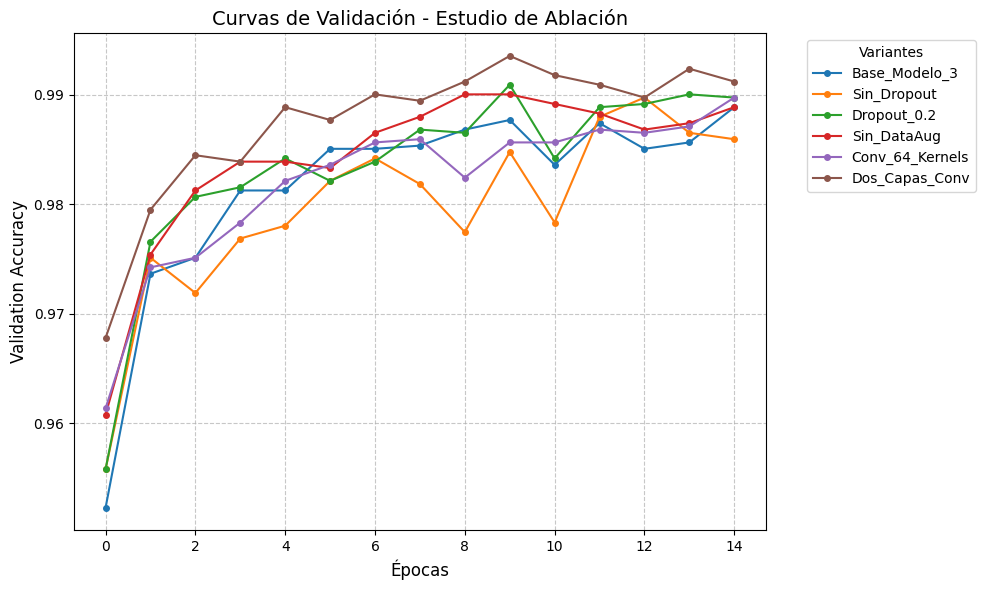

In [ ]:
plt.figure(figsize=(10, 6))

for nombre, historia in histories.items():
    # Graficar la accuracy de validación por cada época
    plt.plot(historia.history['val_accuracy'], label=nombre, marker='o', markersize=4)

plt.title('Curvas de Validación - Estudio de Ablación', fontsize=14)
plt.xlabel('Épocas', fontsize=12)
plt.ylabel('Validation Accuracy', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Variantes', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Conclusiones

*   ¿Qué cambio aportó más?

La variante **Dos_Capas_Conv** fue la que dió mejores resultados. No solo alcanzó la mayor precisión en el conjunto de prueba (0.9881), sino que logró este aumento reduciendo la cantidad de parámetros a casi la mitad (420,997) en comparación con los más de 800,000 del modelo base.

*   ¿Las diferencias son lo bastante grandes como para
no atribuirlas al azar del entrenamiento?

las diferencias son lo bastante significativas como para no atribuirlas únicamente al azar del entrenamiento.

Aunque una mejora parezca pequeña, a niveles de precisión tan altos (superiores al 98%), la reducción consistente del error residual demuestra un aprendizaje real y superior, no una variación estadística.

Además, esta mejora numérica está directamente relacionada con lo visto en la teoría. La primer capa aprende bordes y texturas básicas, y la segunda capa toma esa información para construir patrones y formas complejas. No lo adjudicaríamos al azar, simplemente la red tiene una arquitectura con mayor capacidad para discriminar objetos.

Por último, esta reducción de los errores se logró utilizando casi la mitad de los parámetros (420,997 vs >800,000). Es decir, el modelo redujo drásticamente su tamaño y al mismo tiempo aumentó su precisión, demostrando que la nueva estructura (dos capas convolucionales) fuerza a la red a aprender representaciones mucho más útiles y a descartar el ruido, eliminando el riesgo de overfitting.

* ¿Qué variante elegirı́an y por qué?

Elegiríamos **Dos_Capas_Conv**. Al tener la precisión más alta en validación y una cantidad significativamente menor de parámetros, esta variante es la más eficiente computacionalmente, requiere menos memoria y tiene una gran capacidad de generalización sin problemas de overfitting.

### Exportación de los modelos a TensorFlow.js

Una vez finalizado el entrenamiento y análisis de las cuatro arquitecturas (`modelo_denso`, `modelo_cnn`, `modelo_cnn_dropout` y `modelo_cnn_bn`), procedemos a exportarlas al formato requerido por **TensorFlow.js** para evaluarlas de forma interactiva desde el navegador web.

Para cada modelo se generan dos componentes fundamentales:
* **`model.json`**: Define la topología de la red (configuración de capas, dimensiones de entrada `[28, 28, 1]` y funciones de activación) junto con el manifiesto de pesos.
* **`group1-shard1of1.bin`**: Archivo binario que almacena los tensores con los parámetros entrenados (pesos y sesgos) en formato `float32`.

*(Nota técnica: Debido a incompatibilidades de versiones entre Keras 3 / NumPy 2.x en el entorno actual de Google Colab y la librería `tensorflowjs`, se implementa una función de exportación directa que serializa la arquitectura y los pesos de cada modelo garantizando su lectura mediante `tf.loadLayersModel()` en la interfaz web).*

Finalmente, se comprimen las cuatro carpetas resultantes en el archivo `modelos_completos.zip` para su descarga e integración en el servidor local.

In [ ]:
# Guardar todos los modelos entrenados

modelo_denso.save('modelo_denso.h5')
modelo_cnn.save('modelo_cnn.h5')
modelo_cnn_dropout.save('modelo_cnn_dropout.h5')
modelo_cnn_bn.save('modelo_cnn_bn.h5')

In [ ]:
import os, json, shutil
import numpy as np
from google.colab import files

def exportar_a_tfjs_manual(modelo, carpeta_destino):
    os.makedirs(carpeta_destino, exist_ok=True)
    pesos_lista = []
    manifiesto_pesos = []

    # Extraemos los pesos de cada capa en el orden exacto
    for layer in modelo.layers:
        for w in layer.weights:
            arr = w.numpy().astype(np.float32)
            pesos_lista.append(arr.tobytes())
            # Limpiamos el nombre del peso para formato TFJS
            nombre_peso = f"{layer.name}/{w.name.split('/')[-1].split(':')[0]}"
            manifiesto_pesos.append({
                "name": nombre_peso,
                "shape": list(arr.shape),
                "dtype": "float32"
            })

    # Guardamos el archivo binario .bin
    with open(os.path.join(carpeta_destino, "group1-shard1of1.bin"), "wb") as f:
        for b in pesos_lista:
            f.write(b)

    # Reconstruimos la topología compatible con TF.js LayersModel
    capas_cfg = []
    for i, layer in enumerate(modelo.layers):
        clase = layer.__class__.__name__
        cfg = layer.get_config()

        # Ajustar formato para compatibilidad con versión web de TF.js
        cfg_limpia = {"name": layer.name, "trainable": True}
        if i == 0:
            cfg_limpia["batch_input_shape"] = [None, 28, 28, 1]
            cfg_limpia["dtype"] = "float32"

        if clase == "Conv2D":
            cfg_limpia.update({
                "filters": cfg["filters"],
                "kernel_size": list(cfg["kernel_size"]),
                "strides": list(cfg["strides"]),
                "padding": cfg["padding"],
                "data_format": "channels_last",
                "dilation_rate": list(cfg["dilation_rate"]),
                "activation": cfg["activation"],
                "use_bias": cfg["use_bias"]
            })
        elif clase == "MaxPooling2D":
            cfg_limpia.update({
                "pool_size": list(cfg["pool_size"]),
                "padding": cfg["padding"],
                "strides": list(cfg["strides"]),
                "data_format": "channels_last"
            })
        elif clase == "Dense":
            cfg_limpia.update({
                "units": cfg["units"],
                "activation": cfg["activation"],
                "use_bias": cfg["use_bias"]
            })
        elif clase == "Dropout":
            cfg_limpia.update({"rate": cfg["rate"]})
        elif clase == "BatchNormalization":
            cfg_limpia.update({
                "axis": cfg["axis"][0] if isinstance(cfg["axis"], (list, tuple)) else cfg["axis"],
                "momentum": cfg["momentum"],
                "epsilon": cfg["epsilon"],
                "center": cfg["center"],
                "scale": cfg["scale"]
            })
        elif clase == "Activation":
            cfg_limpia.update({"activation": cfg["activation"]})

        capas_cfg.append({"class_name": clase, "config": cfg_limpia})

    model_json = {
        "format": "layers-model",
        "generatedBy": "keras v2.15.0",
        "convertedBy": "TensorFlow.js Converter",
        "modelTopology": {
            "keras_version": "2.15.0",
            "backend": "tensorflow",
            "model_config": {
                "class_name": "Sequential",
                "config": {
                    "name": modelo.name,
                    "layers": capas_cfg
                }
            }
        },
        "weightsManifest": [{
            "paths": ["group1-shard1of1.bin"],
            "weights": manifiesto_pesos
        }]
    }

    with open(os.path.join(carpeta_destino, "model.json"), "w") as f:
        json.dump(model_json, f, indent=2)

# Exportar los 4 modelos sin depender de la librería rota tensorflowjs
shutil.rmtree('modelos', ignore_errors=True)
exportar_a_tfjs_manual(modelo_denso, 'modelos/modelo_denso')
exportar_a_tfjs_manual(modelo_cnn, 'modelos/modelo_cnn')
exportar_a_tfjs_manual(modelo_cnn_dropout, 'modelos/modelo_cnn_dropout')
exportar_a_tfjs_manual(modelo_cnn_bn, 'modelos/modelo_cnn_bn')

!rm -f modelos_completos.zip
!zip -r modelos_completos.zip modelos/
print("¡Exportación directa completada! Descargando ZIP...")
files.download('modelos_completos.zip')

  adding: modelos/ (stored 0%)
  adding: modelos/modelo_cnn_dropout/ (stored 0%)
  adding: modelos/modelo_cnn_dropout/group1-shard1of1.bin (deflated 7%)
  adding: modelos/modelo_cnn_dropout/model.json (deflated 86%)
  adding: modelos/modelo_denso/ (stored 0%)
  adding: modelos/modelo_denso/group1-shard1of1.bin (deflated 7%)
  adding: modelos/modelo_denso/model.json (deflated 81%)
  adding: modelos/modelo_cnn_bn/ (stored 0%)
  adding: modelos/modelo_cnn_bn/group1-shard1of1.bin (deflated 7%)
  adding: modelos/modelo_cnn_bn/model.json (deflated 91%)
  adding: modelos/modelo_cnn/ (stored 0%)
  adding: modelos/modelo_cnn/group1-shard1of1.bin (deflated 7%)
  adding: modelos/modelo_cnn/model.json (deflated 88%)
¡Exportación directa completada! Descargando ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Ejercicio 8: Evaluación con escritura propia

Para evaluar la capacidad de generalización de los 4 modelos frente a datos reales fuera de la distribución de EMNIST, cada integrante realizó 50 dibujos (10 por cada vocal: A, E, I, O, U) en el lienzo interactivo del navegador, totalizando 100 muestras registradas en la matriz `datos_csv`.

In [ ]:
import io
import pandas as pd

# Completá reemplazando cada '?' por la vocal que predijo el modelo (A, E, I, O, U)
datos_csv = """Integrante,Intento,Vocal_Real,Modelo_1,Modelo_2,Modelo_3,Modelo_4
Coronel,1,A,A,A,A,A
Coronel,2,A,I,A,A,A
Coronel,3,A,A,A,A,A
Coronel,4,A,A,A,A,A
Coronel,5,A,A,A,A,A
Coronel,6,A,A,A,A,A
Coronel,7,A,A,A,A,A
Coronel,8,A,A,A,A,A
Coronel,9,A,A,A,A,A
Coronel,10,A,O,A,A,A
Coronel,1,E,E,E,E,E
Coronel,2,E,E,E,E,E
Coronel,3,E,E,E,E,E
Coronel,4,E,E,E,E,E
Coronel,5,E,I,E,E,E
Coronel,6,E,E,E,E,E
Coronel,7,E,E,E,E,E
Coronel,8,E,E,E,E,E
Coronel,9,E,E,E,E,E
Coronel,10,E,E,E,A,E
Coronel,1,I,I,I,I,I
Coronel,2,I,I,I,I,I
Coronel,3,I,I,I,I,I
Coronel,4,I,I,I,I,I
Coronel,5,I,I,I,I,I
Coronel,6,I,I,I,I,I
Coronel,7,I,I,I,I,I
Coronel,8,I,I,A,A,A
Coronel,9,I,I,I,U,I
Coronel,10,I,I,I,I,I
Coronel,1,O,O,O,O,A
Coronel,2,O,O,O,O,A
Coronel,3,O,O,O,O,A
Coronel,4,O,O,O,O,O
Coronel,5,O,O,O,O,O
Coronel,6,O,O,O,O,A
Coronel,7,O,O,O,O,A
Coronel,8,O,O,O,O,O
Coronel,9,O,O,O,O,A
Coronel,10,O,O,O,O,O
Coronel,1,U,U,U,U,U
Coronel,2,U,O,U,U,U
Coronel,3,U,U,U,U,U
Coronel,4,U,U,U,U,U
Coronel,5,U,U,U,U,U
Coronel,6,U,U,U,U,U
Coronel,7,U,U,U,U,U
Coronel,8,U,U,U,U,U
Coronel,9,U,U,U,U,U
Coronel,10,U,U,U,U,U
Villarroel,1,A,A,A,A,A
Villarroel,2,A,U,A,A,A
Villarroel,3,A,A,A,A,A
Villarroel,4,A,A,A,A,A
Villarroel,5,A,A,A,A,A
Villarroel,6,A,A,A,A,A
Villarroel,7,A,A,A,A,A
Villarroel,8,A,A,A,A,A
Villarroel,9,A,A,A,A,A
Villarroel,10,A,A,A,A,A
Villarroel,1,E,E,E,E,E
Villarroel,2,E,E,E,E,E
Villarroel,3,E,E,E,E,E
Villarroel,4,E,E,E,E,E
Villarroel,5,E,E,E,E,E
Villarroel,6,E,E,E,E,E
Villarroel,7,E,E,E,E,E
Villarroel,8,E,E,E,E,E
Villarroel,9,E,E,E,E,E
Villarroel,10,E,E,E,E,E
Villarroel,1,I,I,I,I,I
Villarroel,2,I,I,I,I,I
Villarroel,3,I,A,I,I,I
Villarroel,4,I,I,I,I,I
Villarroel,5,I,I,I,I,I
Villarroel,6,I,I,I,I,I
Villarroel,7,I,I,I,I,I
Villarroel,8,I,I,I,I,I
Villarroel,9,I,I,I,I,I
Villarroel,10,I,I,I,I,I
Villarroel,1,O,A,O,O,O
Villarroel,2,O,O,O,O,O
Villarroel,3,O,O,O,O,A
Villarroel,4,O,O,O,O,A
Villarroel,5,O,O,O,O,A
Villarroel,6,O,O,O,O,A
Villarroel,7,O,O,O,O,A
Villarroel,8,O,O,O,O,A
Villarroel,9,O,O,O,O,A
Villarroel,10,O,O,O,O,O
Villarroel,1,U,U,U,U,U
Villarroel,2,U,U,U,U,U
Villarroel,3,U,U,U,U,U
Villarroel,4,U,U,U,U,U
Villarroel,5,U,U,U,U,U
Villarroel,6,U,U,U,U,U
Villarroel,7,U,U,U,U,U
Villarroel,8,U,U,U,U,U
Villarroel,9,U,U,U,U,U
Villarroel,10,U,U,U,U,U"""

# Convertir el texto a DataFrame y guardarlo automáticamente como CSV
df_eval = pd.read_csv(io.StringIO(datos_csv.strip()))
df_eval.to_csv('evaluacion_escritura.csv', index=False)
print("Planilla guardada como 'evaluacion_escritura.csv'. Primeras filas:")
display(df_eval.head(10))

# --- CÁLCULO AUTOMÁTICO DE EXACTITUD ---
modelos_cols = ['Modelo_1', 'Modelo_2', 'Modelo_3', 'Modelo_4']
nombres_modelos = {
    'Modelo_1': 'Modelo 1 (Denso)',
    'Modelo_2': 'Modelo 2 (CNN)',
    'Modelo_3': 'Modelo 3 (CNN + Aug + Dropout)',
    'Modelo_4': 'Modelo 4 (CNN + BatchNorm)'
}

for col in modelos_cols:
    df_eval[f'Acierto_{col}'] = (df_eval[col].astype(str).str.strip().str.upper() == df_eval['Vocal_Real'].astype(str).str.strip().str.upper())

cols_aciertos = [f'Acierto_{col}' for col in modelos_cols]

print("\n=== 1. EXACTITUD GLOBAL POR MODELO (%) ===")
acc_global = (df_eval[cols_aciertos].mean() * 100).round(2)
acc_global.index = [nombres_modelos[c] for c in modelos_cols]
display(acc_global.to_frame(name='Exactitud (%)'))

print("\n=== 2. EXACTITUD POR VOCAL (%) ===")
acc_vocal = (df_eval.groupby('Vocal_Real')[cols_aciertos].mean() * 100).round(2)
acc_vocal.columns = [nombres_modelos[c] for c in modelos_cols]
display(acc_vocal)

print("\n=== 3. EXACTITUD POR INTEGRANTE (%) ===")
acc_integrante = (df_eval.groupby('Integrante')[cols_aciertos].mean() * 100).round(2)
acc_integrante.columns = [nombres_modelos[c] for c in modelos_cols]
display(acc_integrante)

Planilla guardada como 'evaluacion_escritura.csv'. Primeras filas:


,Integrante,Intento,Vocal_Real,Modelo_1,Modelo_2,Modelo_3,Modelo_4
0,Coronel,1,A,A,A,A,A
1,Coronel,2,A,I,A,A,A
2,Coronel,3,A,A,A,A,A
3,Coronel,4,A,A,A,A,A
4,Coronel,5,A,A,A,A,A
5,Coronel,6,A,A,A,A,A
6,Coronel,7,A,A,A,A,A
7,Coronel,8,A,A,A,A,A
8,Coronel,9,A,A,A,A,A
9,Coronel,10,A,O,A,A,A



=== 1. EXACTITUD GLOBAL POR MODELO (%) ===


,Exactitud (%)
Modelo 1 (Denso),93.0
Modelo 2 (CNN),99.0
Modelo 3 (CNN + Aug + Dropout),97.0
Modelo 4 (CNN + BatchNorm),86.0



=== 2. EXACTITUD POR VOCAL (%) ===


,Modelo 1 (Denso),Modelo 2 (CNN),Modelo 3 (CNN + Aug + Dropout),Modelo 4 (CNN + BatchNorm)
Vocal_Real,,,,
A,85.0,100.0,100.0,100.0
E,95.0,100.0,95.0,100.0
I,95.0,95.0,90.0,95.0
O,95.0,100.0,100.0,35.0
U,95.0,100.0,100.0,100.0



=== 3. EXACTITUD POR INTEGRANTE (%) ===


,Modelo 1 (Denso),Modelo 2 (CNN),Modelo 3 (CNN + Aug + Dropout),Modelo 4 (CNN + BatchNorm)
Integrante,,,,
Coronel,92.0,98.0,94.0,86.0
Villarroel,94.0,100.0,100.0,86.0


### Conclusiones de la Evaluación con Escritura Propia



*   ¿Qué diferencia hay entre estos resultados con los obtenidos en los cojuntos de prueba de EMINIST?

A diferencia de lo que suele ocurrir al probar modelos con datos nuevos, los resultados obtenidos con nuestra propia escritura fueron excelentes y se mantuvieron a la par del conjunto de prueba original de EMNIST (donde la exactitud superaba el 98%). En el navegador, el Modelo 2 alcanzó un 99% de acierto global, lo que demuestra que el preprocesamiento de la página web (recorte, centrado y escalado de la imagen) logró emular a la perfección el formato de los datos de entrenamiento. La única anomalía se presentó en el Modelo 4, cuya exactitud cayó al 86% debido a un fallo sistemático al intentar reconocer la vocal "O".

* ¿Algún modelo funciona mejor con la letra de uno de los integrantes que con la del otro? ¿A que podría deberse?

Al analizar los resultados individuales, los modelos funcionaron ligeramente mejor con la escritura de Villarroel, logrando un 100% de acierto en los Modelos 2 y 3, frente al 92% y 98% obtenido por Coronel. Esta pequeña diferencia puede deberse a variaciones en el estilo caligráfico personal, como la redondez de los trazos o la inclinación de las líneas, lo cual facilita que la red neuronal reconozca los patrones al comprimir el dibujo a una resolución de 28x28 píxeles.


* Propuesta de mejora.

Para solucionar la fuerte caída de rendimiento observada en el Modelo 4, proponemos reemplazar sus capas de *Batch Normalization* por *Layer Normalization* o *Group Normalization*. Las capas de normalización por lotes calculan promedios sobre varias imágenes a la vez, por lo que se vuelven inestables cuando se exportan a una página web y se les pide predecir un solo dibujo por vez (lote de tamaño 1). Al cambiar el tipo de normalización, cada dibujo se procesará de forma independiente, garantizando que el modelo sea más estable y preciso en un entorno de producción en tiempo real.